# Sentiment classification of product reviews
TF-IDF + logistic regression on a review corpus.

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from scipy import stats
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
df = pd.read_csv("reviews.csv")
print(f"Loaded {len(df)} documents")
df.shape

Loaded 420 documents


(420, 5)

In [3]:
df["label"].value_counts()

positive    252
negative    168
Name: label, dtype: int64

In [4]:
vectorizer = TfidfVectorizer(max_features=5000)
X_text = vectorizer.fit_transform(df["text"])
scaler = StandardScaler(with_mean=False)
X = scaler.fit_transform(X_text)
y = df["label"]
print("Feature matrix:", X.shape)

Feature matrix: (420, 5000)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train size:", X_train.shape[0], "Test size:", X_test.shape[0])

Train size: 336 Test size: 84


In [12]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
preds = model.predict(X_test)
acc = accuracy_score(y_test, preds)
f1 = f1_score(y_test, preds, average="macro")
print(f"Test accuracy: {acc:.4f}")
print(f"Macro F1: {f1:.3f}")
TARGET_F1 = 0.80
print("Meets target:", f1 >= TARGET_F1)

Test accuracy: 0.8452
Macro F1: 0.801
Meets target: True


In [6]:
scores_lr = [0.84, 0.83, 0.86, 0.82, 0.85]
scores_svm = [0.81, 0.82, 0.80, 0.83, 0.79]
t, p = stats.ttest_ind(scores_lr, scores_svm)
print(f"t = {t:.3f}, p-value = {p:.3f}")

t = 2.312, p-value = 0.048


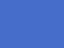

In [7]:
val_loss = [0.69, 0.52, 0.44, 0.47, 0.41, 0.43]
plt.plot(range(1, 7), val_loss, label="validation loss")
plt.xlabel("Epoch")
plt.title("Validation loss per epoch")
plt.legend()
plt.show()

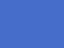

In [8]:
models = ["LogReg", "SVM", "NB"]
scores = [0.845, 0.83, 0.81]
plt.bar(models, scores)
plt.ylim(0.8, 0.86)
plt.ylabel("Accuracy")
plt.title("Model comparison")
plt.show()

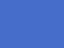

In [9]:
from sklearn.manifold import TSNE
emb = TSNE(n_components=2, perplexity=30).fit_transform(X.toarray())
plt.scatter(emb[:, 0], emb[:, 1], c=(y == "positive"), s=8)
plt.title("t-SNE of TF-IDF features")
plt.show()